# Homework 2

## Importing Relevant Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Downloading Dataset

In [2]:
%%script true # Skips the cell to prevent repeated dataset downloads.

data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
!wget $data

--2026-10-11 22:55:23--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.01s   

2026-10-11 22:55:23 (53.2 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



## Loading the Dataset

In [2]:
df_raw = pd.read_csv('car_fuel_efficiency_2026.csv')
df = df_raw.copy() # This copies df_raw into df.

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


## Preparing the Dataset

### Homework requires the use of the following the columns: engine_displacement, horsepower, vehicle_weight, model_year and fuel_efficiency_mpg.

In [4]:
df_columns = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']
df_columns

['engine_displacement',
 'horsepower',
 'vehicle_weight',
 'model_year',
 'fuel_efficiency_mpg']

In [5]:
df = df[df_columns]
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## Describing the Dataset

In [6]:
df.shape

(10000, 5)

In [7]:
len(df)

10000

In [8]:
for col in df.columns:
    print(col)
    print(df[col].nunique())
    print()

engine_displacement
127

horsepower
153

vehicle_weight
176

model_year
50

fuel_efficiency_mpg
188



In [9]:
df.dtypes

engine_displacement      int64
horsepower             float64
vehicle_weight           int64
model_year               int64
fuel_efficiency_mpg    float64
dtype: object

## Exploratory Data Analysis (EDA)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

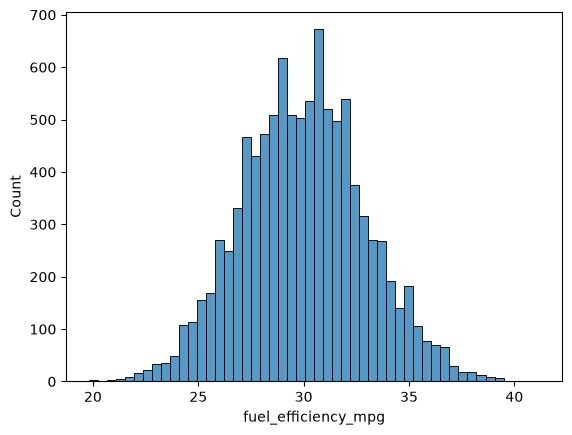

In [10]:
axs = sns.histplot(df.fuel_efficiency_mpg, bins=50)
axs

In [11]:
# Converting the values of fuel_efficiency_mpg to log.
fuel_efficiency_mpg_log = np.log1p(df.fuel_efficiency_mpg)

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

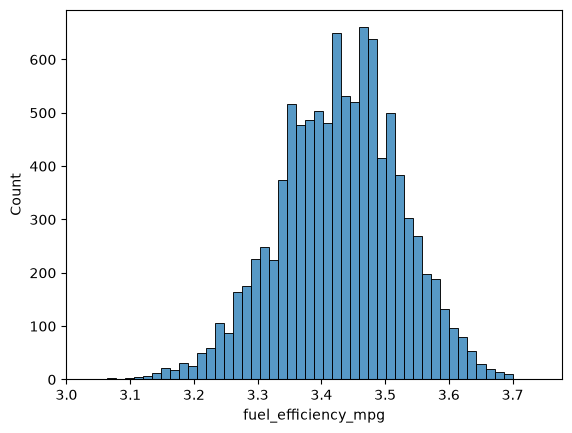

In [12]:
bxs = sns.histplot(fuel_efficiency_mpg_log, bins=50)
bxs

Comparing the original and log-transformed values, both plots exhibit approximately normal distributions, with no significant long tails. Nevertheless, the model will be trained using the log-transformed values due to their potential to improve prediction accuracy.

## Question 1

#### There's one column with missing values. What is it?

In [13]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

##### The 'horsepower' column has missing values. 877 values are missing.

## Question 2

#### What's the median (50% percentile) for variable 'horsepower'?

In [14]:
horsepower_median = df['horsepower'].median()
horsepower_median

np.float64(254.0)

##### The median (50% percentile) for variable 'horsepower' is 254.

## Prepare snd Split the Dataset

In [15]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train + n_val].copy()
df_test = df_shuffled.iloc[n_train + n_val:].copy()

In [16]:
n_train, n_val, n_test

(6000, 2000, 2000)

In [17]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

## Question 3

##### We need to deal with missing values for the column from Q1.
##### We have two options: fill it with 0 or with the mean of this variable.
##### Try both options. For each, train a linear regression model without regularization using the code from the lessons.
##### For computing the mean, use the training only!
##### Use the validation dataset to evaluate the models and compare the RMSE of each option.
##### Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.
##### Which option gives better RMSE?

##### Options:
    With 0
    With mean
    Both are equally good

#### Filling Missing Values for Column 'horsepower'

In [18]:
zero_hp = 0 
mean_hp = df_train['horsepower'].mean()
mean_hp

np.float64(254.46338337605272)

In [19]:
splits = {
    'train': df_train,
    'val': df_val,
    'test': df_test
}

In [20]:
# A function that copies dataframe and fills missing values based on the specified value.

def missing_value_fillna(x):

    if x == 0:
        fill_value = zero_hp

    elif x == 'mean':
        fill_value = mean_hp

    else:
        raise ValueError("Choose either 'zero' or 'mean'")

    results = {}

    for name, dataframe in splits.items():

        results[name] = dataframe.copy()

        results[name]['horsepower'] = (
            results[name]['horsepower'].fillna(fill_value)
        )

        print(
            f"Missing horsepower values in {name}: "
            f"{results[name]['horsepower'].isna().sum()}"
        )

    return results

#### Filling Missing Values with 0

In [21]:
zero_splits = missing_value_fillna(0)

Missing horsepower values in train: 0
Missing horsepower values in val: 0
Missing horsepower values in test: 0


In [22]:
df_train_zero = zero_splits['train']
df_val_zero = zero_splits['val']
df_test_zero = zero_splits['test']

In [23]:
df_train_zero.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,0.0,4150,1997,30.6
4,2340,269.0,4400,2001,30.7


#### Filling Missing Values with Mean

In [24]:
mean_splits = missing_value_fillna('mean')

Missing horsepower values in train: 0
Missing horsepower values in val: 0
Missing horsepower values in test: 0


In [25]:
df_train_mean = mean_splits['train']
df_val_mean = mean_splits['val']
df_test_mean = mean_splits['test']

In [26]:
df_train_mean.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.000000,3790,2015,32.5
1,2000,224.000000,4380,1992,29.1
2,2330,286.000000,4090,2022,34.1
3,2300,254.463383,4150,1997,30.6
4,2340,269.000000,4400,2001,30.7


#### Retrieving the Targets(y values)

In [27]:
# Dataframe where fillna was 0.
y_train_zero_orig = df_train_zero.fuel_efficiency_mpg.values
y_val_zero_orig = df_val_zero.fuel_efficiency_mpg.values
y_test_zero_orig = df_test_zero.fuel_efficiency_mpg.values  

y_train_zero = np.log1p(df_train_zero.fuel_efficiency_mpg.values)
y_val_zero = np.log1p(df_val_zero.fuel_efficiency_mpg.values)
y_test_zero = np.log1p(df_test_zero.fuel_efficiency_mpg.values)  

del df_train_zero['fuel_efficiency_mpg']
del df_val_zero['fuel_efficiency_mpg']
del df_test_zero['fuel_efficiency_mpg']

# Dataframe where fillna was mean.
y_train_mean_orig = df_train_mean.fuel_efficiency_mpg.values
y_val_mean_orig = df_val_mean.fuel_efficiency_mpg.values
y_test_mean_orig = df_test_mean.fuel_efficiency_mpg.values  

y_train_mean = np.log1p(df_train_mean.fuel_efficiency_mpg.values)
y_val_mean = np.log1p(df_val_mean.fuel_efficiency_mpg.values)
y_test_mean = np.log1p(df_test_mean.fuel_efficiency_mpg.values)

del df_train_mean['fuel_efficiency_mpg']
del df_val_mean['fuel_efficiency_mpg']
del df_test_mean['fuel_efficiency_mpg']

## Feature Engineering

In [28]:
# Creating column 'model_age' from 'model_year'.
# The year reference used is 2026.

reference_year = 2026

def model_diff(df_list):
    for data in df_list:
        data['model_age'] = reference_year - data['model_year']


In [29]:
df_list = [df_train_zero, df_val_zero, df_test_zero, df_train_mean, df_val_mean, df_test_mean]
model_diff(df_list)

## Linear Regression Model

In [30]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

#### Solution

In [31]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_age']

In [32]:
def prepare_X(df):
    df_num = df[base]
    # df_num = df_num.fillna(0) -- Already filled all missing values.
    X = df_num.values
    return X

In [33]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

#### For Dataset where missing values were replace with 0.

In [34]:
X_train_zero = prepare_X(df_train_zero)
w_0, w = train_linear_regression(X_train_zero, y_train_zero)

In [35]:
y_train_pred_zero_log = w_0 + X_train_zero.dot(w)
y_train_pred_zero_mpg = np.expm1(y_train_pred_zero_log)
print('train:', round(rmse(y_train_zero_orig, y_train_pred_zero_mpg), 3))

X_val_zero = prepare_X(df_val_zero)
y_val_pred_zero_log = w_0 + X_val_zero.dot(w)
y_val_pred_zero_mpg = np.expm1(y_val_pred_zero_log)
print('validation:', round(rmse(y_val_zero_orig, y_val_pred_zero_mpg), 3))

train: 2.205
validation: 2.21


#### For Dataset where missing values were replace with mean.

In [36]:
X_train_mean = prepare_X(df_train_mean)
w_0, w = train_linear_regression(X_train_mean, y_train_mean)

In [37]:
y_train_pred_mean_log = w_0 + X_train_mean.dot(w)
y_train_pred_mean_mpg = np.expm1(y_train_pred_mean_log)
print('train:', round(rmse(y_train_mean_orig, y_train_pred_mean_mpg), 3))

X_val_mean = prepare_X(df_val_mean)
y_val_pred_mean_log = w_0 + X_val_mean.dot(w)
y_val_pred_mean_mpg = np.expm1(y_val_pred_mean_log)
print('validation:', round(rmse(y_val_mean_orig, y_val_pred_mean_mpg), 3))

train: 2.203
validation: 2.207


#### Both approaches are good as their RMSE values are similar and very close to 0.

## Question 4

##### Now let's train a regularized linear regression.
##### For this question, fill the NAs with 0.
##### Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
##### Use RMSE to evaluate the model on the validation dataset.
##### Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
##### Which r gives the best RMSE?
##### If multiple options give the same best RMSE, select the smallest r.

##### Options:

    0
    0.01
    0.1
    1
    5
    10
    100

#### Regularization

In [38]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [39]:
# Regularisation values
reg_values = [0, 0.01, 0.1, 1, 5, 10, 100]

# Prepare validation features
X_val_zero = prepare_X(df_val_zero)

# Dictionary to store RMSE scores
scores = {}

for r in reg_values:

    # Train regularised linear regression model
    w_0, w = train_linear_regression_reg(
        X_train_zero, y_train_zero, r=r
    )

    # Training predictions and RMSE
    y_pred_train_log = w_0 + X_train_zero.dot(w)
    y_pred_train_mpg = np.expm1(y_pred_train_log)
    train_rmse = rmse(y_train_zero_orig, y_pred_train_mpg)

    # Validation predictions and RMSE
    y_pred_val_log = w_0 + X_val_zero.dot(w)
    y_pred_val_mpg = np.expm1(y_pred_val_log)
    val_rmse = rmse(y_val_zero_orig, y_pred_val_mpg)

    # Store validation RMSE (unrounded)
    scores[r] = val_rmse

    # Display results
    print(f"When r = {r}")
    print("Train RMSE = ", round(train_rmse, 4))
    print("Validation RMSE = ", round(val_rmse, 4))
    print()

# Identify the best regularisation value
best_r = min(scores, key=scores.get)

print("-----------------------------")
print(f"Best regularisation (r): {best_r}")
print(f"Lowest validation RMSE: {round(scores[best_r], 4)}")

When r = 0
Train RMSE =  2.2052
Validation RMSE =  2.2105

When r = 0.01
Train RMSE =  2.2052
Validation RMSE =  2.2104

When r = 0.1
Train RMSE =  2.2053
Validation RMSE =  2.2098

When r = 1
Train RMSE =  2.2294
Validation RMSE =  2.2276

When r = 5
Train RMSE =  2.629
Validation RMSE =  2.6133

When r = 10
Train RMSE =  3.2752
Validation RMSE =  3.26

When r = 100
Train RMSE =  6.8361
Validation RMSE =  6.8783

-----------------------------
Best regularisation (r): 0.1
Lowest validation RMSE: 2.2098


## Question 5

##### We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
##### Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
##### For each seed, do the train/validation/test split with 60%/20%/20% distribution.
##### Fill the missing values with 0 and train a model without regularization.
##### For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
##### What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
##### Round the result to 3 decimal digits (round(std, 3))
##### What's the value of std?

    0.006
    0.016
    0.029
    0.036
##### Note: Standard deviation shows how different the values are. If it's low, then all values are approximately the same. If it's high, the values are different. If standard deviation of scores is low, then our model is stable.

In [40]:
def seeding(seeding_values):

    results = {}

    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    for seed in seeding_values:

        # Shuffle data
        np.random.seed(seed)
        idx = np.arange(n)
        np.random.shuffle(idx)

        df_shuffled = df.iloc[idx]

        # Split datasets and fill missing values
        df_train = df_shuffled.iloc[:n_train].copy().reset_index(drop=True)
        df_val = df_shuffled.iloc[n_train:n_train + n_val].copy().reset_index(drop=True)
        df_test = df_shuffled.iloc[n_train + n_val:].copy().reset_index(drop=True)

        # Feature Engineering
        df_list = [df_train, df_val, df_test]
        model_diff(df_list)

        # Fill missing feature values with zero
        for data in df_list:
            data.fillna(0, inplace=True)

        # Extract original target values
        y_train_orig = df_train['fuel_efficiency_mpg'].values
        y_val_orig = df_val['fuel_efficiency_mpg'].values
        y_test_orig = df_test['fuel_efficiency_mpg'].values

        # Log-transform target values
        y_train = np.log1p(y_train_orig)
        y_val = np.log1p(y_val_orig)
        y_test = np.log1p(y_test_orig)

        # Remove target column from features
        df_train = df_train.drop(columns=['fuel_efficiency_mpg'])
        df_val = df_val.drop(columns=['fuel_efficiency_mpg'])
        df_test = df_test.drop(columns=['fuel_efficiency_mpg'])

        # Store results for each seed
        results[seed] = {
            'train': df_train,
            'val': df_val,
            'test': df_test,
            'y_train_orig': y_train_orig,
            'y_val_orig': y_val_orig,
            'y_test_orig': y_test_orig,
            'y_train': y_train,
            'y_val': y_val,
            'y_test': y_test
        }

        X_train = prepare_X(df_train)
        X_val = prepare_X(df_val)
        w_0, w = train_linear_regression(X_train, y_train)
        y_pred_train_log = w_0 + X_train.dot(w)
        y_pred_train_mpg = np.expm1(y_pred_train_log)
        y_pred_val_log = w_0 + X_val.dot(w)
        y_pred_val_mpg = np.expm1(y_pred_val_log)
        score_train = rmse(y_train_orig, y_pred_train_mpg)
        score_val = rmse(y_val_orig, y_pred_val_mpg)
        results[seed]['rmse_train'] = score_train
        results[seed]['rmse_val'] = score_val

        print(f"Seed: {seed}")
        print(f"Train RMSE = {round(score_train, 3)}")
        print(f"Validation RMSE = {round(score_val, 3)}")
        print()

    return results

In [41]:
seeding_values = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

splits = seeding(seeding_values)

Seed: 0
Train RMSE = 2.206
Validation RMSE = 2.246

Seed: 1
Train RMSE = 2.208
Validation RMSE = 2.206

Seed: 2
Train RMSE = 2.234
Validation RMSE = 2.169

Seed: 3
Train RMSE = 2.214
Validation RMSE = 2.209

Seed: 4
Train RMSE = 2.206
Validation RMSE = 2.205

Seed: 5
Train RMSE = 2.197
Validation RMSE = 2.25

Seed: 6
Train RMSE = 2.182
Validation RMSE = 2.275

Seed: 7
Train RMSE = 2.214
Validation RMSE = 2.193

Seed: 8
Train RMSE = 2.202
Validation RMSE = 2.217

Seed: 9
Train RMSE = 2.204
Validation RMSE = 2.218



In [42]:
rmse_results = pd.DataFrame({
'seed': seeding_values,
'rmse_train': [
    splits[seed]['rmse_train']
    for seed in seeding_values
],
'rmse_val': [
    splits[seed]['rmse_val']
    for seed in seeding_values
]
})

# Display RMSE results
print()
print('---------------------------------------')
display(rmse_results)

# Calculate standard deviation of validation RMSE
std_val = np.std(rmse_results['rmse_val'])

print()
print("Standard Deviation:", round(std_val, 3))


---------------------------------------


,seed,rmse_train,rmse_val
0,0,2.206292,2.245912
1,1,2.207993,2.205977
2,2,2.234380,2.168720
3,3,2.213938,2.208635
4,4,2.206115,2.205483
5,5,2.196872,2.250189
6,6,2.181514,2.274984
7,7,2.214225,2.192702
8,8,2.202497,2.217444
9,9,2.204462,2.217705



Standard Deviation: 0.029


## Question 6

##### Split the dataset like previously, use seed 9.
##### Combine train and validation datasets.
##### Fill the missing values with 0 and train a model with r=0.001.
##### What's the RMSE on the test dataset?
##### Options:

    0.236
    2.236
    22.10
    221.0

In [43]:
splits[9]['train']

,engine_displacement,horsepower,vehicle_weight,model_year,model_age
0,2320,246.0,4100,2014,12
1,2230,252.0,4250,1998,28
2,2700,276.0,4490,2008,18
3,2220,269.0,4060,2004,22
4,2370,0.0,4690,1979,47
...,...,...,...,...,...
5995,1950,231.0,4150,1989,37
5996,2060,249.0,3910,2012,14
5997,2180,223.0,4360,2014,12
5998,2420,248.0,4080,1977,49


In [44]:
splits[9]['val']

,engine_displacement,horsepower,vehicle_weight,model_year,model_age
0,2410,278.0,4370,2017,9
1,2260,249.0,3980,1984,42
2,2390,273.0,4540,1978,48
3,1990,226.0,4300,1986,40
4,2230,256.0,4060,1998,28
...,...,...,...,...,...
1995,2690,324.0,4510,2023,3
1996,1920,190.0,4000,1998,28
1997,1800,225.0,3980,1994,32
1998,1970,232.0,3560,2009,17


In [45]:
df_train = splits[9]['train'].copy()
df_val = splits[9]['val'].copy()
df_test = splits[9]['test'].copy()

In [46]:
df_combined = pd.concat([df_train, df_val]).reset_index(drop=True)

In [47]:
df_combined

,engine_displacement,horsepower,vehicle_weight,model_year,model_age
0,2320,246.0,4100,2014,12
1,2230,252.0,4250,1998,28
2,2700,276.0,4490,2008,18
3,2220,269.0,4060,2004,22
4,2370,0.0,4690,1979,47
...,...,...,...,...,...
7995,2690,324.0,4510,2023,3
7996,1920,190.0,4000,1998,28
7997,1800,225.0,3980,1994,32
7998,1970,232.0,3560,2009,17


In [48]:
df_test

,engine_displacement,horsepower,vehicle_weight,model_year,model_age
0,2100,258.0,4060,2011,15
1,2160,223.0,4130,2011,15
2,2190,0.0,4030,1975,51
3,2320,257.0,4640,1997,29
4,2330,235.0,4130,1988,38
...,...,...,...,...,...
1995,2260,250.0,4170,1996,30
1996,2300,249.0,4360,2015,11
1997,2240,265.0,4170,1982,44
1998,2380,278.0,4210,1978,48


In [49]:
X_train = prepare_X(df_combined)

X_test = prepare_X(df_test)

In [50]:
y_train_orig = splits[9]['y_train_orig'].copy()
y_train_log = splits[9]['y_train'].copy()

y_val_orig = splits[9]['y_val_orig'].copy()
y_val_log = splits[9]['y_val'].copy()

y_test_orig = splits[9]['y_test_orig'].copy()
y_test_log = splits[9]['y_test'].copy()


In [51]:
y_combined_orig = np.concatenate([y_train_orig, y_val_orig])

y_combined_log = np.concatenate([y_train_log, y_val_log])

In [53]:
r = 0.001

w_0, w = train_linear_regression_reg(
        X_train, y_combined_log, r=r
    )


# Test predictions and RMSE
y_pred_test_log = w_0 + X_test.dot(w)
y_pred_test_mpg = np.expm1(y_pred_test_log)
test_rmse = rmse(y_test_orig, y_pred_test_mpg)

# Display results
print("Test Dataset RMSE = ", round(test_rmse, 4))

Test Dataset RMSE =  2.2398
